# Лабораторная работа №1. Метод обратного распространения ошибки

In [39]:
import time
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

# Скачиваем MNIST, если файла ещё нет
if not Path("mnist.npz").exists():
    urlretrieve(
        "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz",
        "mnist.npz"
    )

# Загружаем данные
with np.load("mnist.npz") as data:
    x_train, y_train = data["x_train"], data["y_train"]
    x_test, y_test = data["x_test"], data["y_test"]

print("Обучающая выборка:", x_train.shape, y_train.shape)
print("Тестовая выборка:", x_test.shape, y_test.shape)
print("Размер изображения:", x_train[0].shape)

Обучающая выборка: (60000, 28, 28) (60000,)
Тестовая выборка: (10000, 28, 28) (10000,)
Размер изображения: (28, 28)


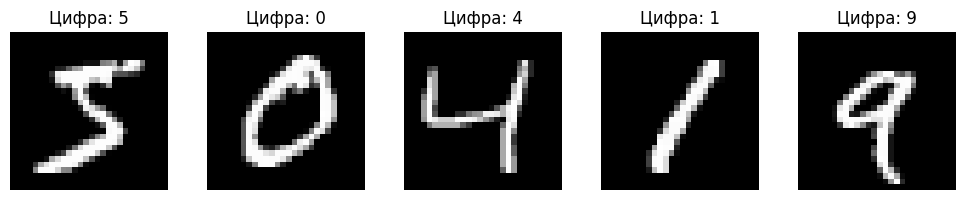

In [40]:
fig, axes = plt.subplots(1, 5, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i], cmap='gray')
    ax.set_title(f'Цифра: {y_train[i]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# Инициализация He
rng = np.random.default_rng(42)
W1 = rng.normal(0, np.sqrt(2 / 784), (784, 300)).astype(np.float32)
b1 = np.zeros(300, dtype=np.float32)
W2 = rng.normal(0, 0.5, (300, 10)).astype(np.float32)
b2 = np.zeros(10, dtype=np.float32)


def relu(z):
    return np.maximum(0, z)


def softmax(z):
    exp_z = np.exp(z)
    return exp_z / exp_z.sum(axis=1, keepdims=True)


def predict(X):
    return np.argmax(relu(X @ W1 + b1) @ W2 + b2, axis=1)

In [42]:
# Подготовка изображений для нейросети
X_train = x_train.reshape(-1, 784).astype(np.float32) / 255.0
X_test = x_test.reshape(-1, 784).astype(np.float32) / 255.0

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (60000, 784)
Тестовая выборка: (10000, 784)


In [ ]:
# Обучение: 20 эпох, batch size = 32, learning rate = 0.1
for epoch in range(1, 21):
    start = time.perf_counter()
    order = rng.permutation(len(X_train))
    for i in range(0, len(order), 32):
        ids = order[i:i + 32]
        X, y = X_train[ids], y_train[ids]

        # Прямой проход
        z1 = X @ W1 + b1
        a1 = relu(z1)
        z2 = a1 @ W2 + b2
        p = softmax(z2)

        # Обратное распространение (softmax + кросс-энтропия)
        output_gradient = p.copy()
        output_gradient[np.arange(len(y)), y] -= 1
        output_gradient /= len(y)
        
        grad_W2 = a1.T @ output_gradient 
        grad_b2 = output_gradient.sum(axis=0)
        
        hidden_gradient = (output_gradient @ W2.T) * (z1 > 0)  # производная ReLU
        
        grad_W1 = X.T @ hidden_gradient
        grad_b1 = hidden_gradient.sum(axis=0)

        # обновление весов и смещений
        W1 -= 0.1 * grad_W1
        b1 -= 0.1 * grad_b1
        W2 -= 0.1 * grad_W2
        b2 -= 0.1 * grad_b2

    error = np.mean(predict(X_train) != y_train) * 100
    print(f'Эпоха {epoch:2d}/20 | Ошибка train: {error:.2f}% | Время: {time.perf_counter() - start:.2f} с')

Эпоха  1/20 | Ошибка train: 2.80% | Время: 0.80 с
Эпоха  2/20 | Ошибка train: 1.78% | Время: 0.77 с
Эпоха  3/20 | Ошибка train: 1.16% | Время: 0.77 с
Эпоха  4/20 | Ошибка train: 0.80% | Время: 0.81 с
Эпоха  5/20 | Ошибка train: 0.53% | Время: 0.84 с
Эпоха  6/20 | Ошибка train: 0.47% | Время: 0.81 с
Эпоха  7/20 | Ошибка train: 0.34% | Время: 0.84 с
Эпоха  8/20 | Ошибка train: 0.18% | Время: 0.78 с
Эпоха  9/20 | Ошибка train: 0.10% | Время: 0.81 с
Эпоха 10/20 | Ошибка train: 0.04% | Время: 0.95 с
Эпоха 11/20 | Ошибка train: 0.04% | Время: 0.82 с
Эпоха 12/20 | Ошибка train: 0.05% | Время: 0.81 с
Эпоха 13/20 | Ошибка train: 0.02% | Время: 0.87 с
Эпоха 14/20 | Ошибка train: 0.01% | Время: 0.79 с
Эпоха 15/20 | Ошибка train: 0.01% | Время: 0.78 с
Эпоха 16/20 | Ошибка train: 0.00% | Время: 0.86 с
Эпоха 17/20 | Ошибка train: 0.00% | Время: 0.78 с
Эпоха 18/20 | Ошибка train: 0.00% | Время: 0.78 с
Эпоха 19/20 | Ошибка train: 0.00% | Время: 0.76 с
Эпоха 20/20 | Ошибка train: 0.00% | Время: 0.75 с


In [44]:
test_error = np.mean(predict(X_test) != y_test) * 100
print(f'Ошибка классификации на тесте: {test_error:.2f}%')
print(f'Точность на тесте: {100 - test_error:.2f}%')

Ошибка классификации на тесте: 1.88%
Точность на тесте: 98.12%


Результаты предсказаний:
1. Предсказание: 8 | Правильный ответ: 8 ✓
2. Предсказание: 7 | Правильный ответ: 7 ✓
3. Предсказание: 2 | Правильный ответ: 2 ✓
4. Предсказание: 5 | Правильный ответ: 5 ✓
5. Предсказание: 7 | Правильный ответ: 7 ✓
6. Предсказание: 6 | Правильный ответ: 6 ✓
7. Предсказание: 5 | Правильный ответ: 5 ✓
8. Предсказание: 3 | Правильный ответ: 3 ✓
9. Предсказание: 4 | Правильный ответ: 4 ✓
10. Предсказание: 8 | Правильный ответ: 8 ✓


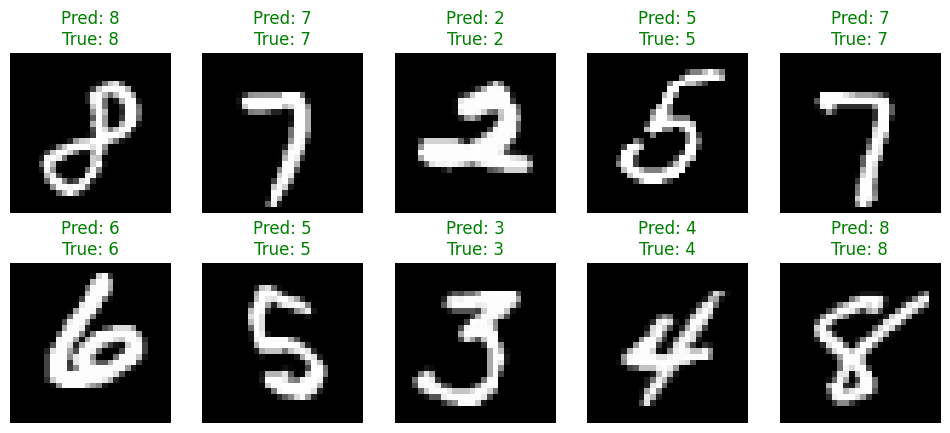

In [45]:
# Выбираем 10 случайных изображений
index = np.random.choice(len(X_test), 10, replace=False)
X_samples = X_test[index]
y_true = y_test[index]

# Получаем предсказания нейросети
y_pred = predict(X_samples)

# Вывод результатов
print("Результаты предсказаний:")
for i in range(len(y_pred)):
    result = "✓" if y_pred[i] == y_true[i] else "✗"
    print(f"{i+1}. Предсказание: {y_pred[i]} | Правильный ответ: {y_true[i]} {result}")

# Визуализация изображений
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flatten()):
    ax.imshow(X_samples[i].reshape(28, 28), cmap="gray")
    color = "green" if y_pred[i] == y_true[i] else "red"
    ax.set_title(f"Pred: {y_pred[i]}\nTrue: {y_true[i]}", color=color)
    ax.axis("off")

plt.show()